
# ETL and Data Pre-processing Pipeline for EV Battery Health and Degradation Analysis

## Objective
The objective of this project is to perform a complete ETL and data pre-processing pipeline on an Electric Vehicle Battery Health dataset.

The project includes:
- Data extraction and profiling
- Missing value handling
- Outlier detection and treatment
- Data integration
- Normalization and standardization
- Discretization and data reduction
- Statistical and class comparison
- Exporting the processed dataset

## Dataset Information
Domain: Electric Vehicle Battery Analysis
Source: Kaggle
Records: 50,000
Attributes: 35
Unique Batteries: 2,600


## 2. Import Required Libraries

In [58]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully")


Libraries imported successfully


## 3. Data Extraction

In [59]:

# Load the primary dataset
df = pd.read_csv("data/ev_battery_health.csv")

# Load the data dictionary
data_dictionary = pd.read_csv("data/data_dictionary.csv")

# Preserve the original dataset
df_raw = df.copy()

print("Dataset loaded successfully")

print("Main Dataset Shape:", df.shape)
print("Data Dictionary Shape:", data_dictionary.shape)


Dataset loaded successfully
Main Dataset Shape: (50000, 35)
Data Dictionary Shape: (35, 5)


## 4. Initial Dataset Profiling

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


Rows: 50000
Columns: 35
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   battery_id                      50000 non-null  str    
 1   observation_id                  50000 non-null  str    
 2   chemistry                       46541 non-null  str    
 3   manufacturer                    47539 non-null  str    
 4   vehicle_model                   46485 non-null  str    
 5   pack_capacity_kwh               47698 non-null  float64
 6   manufacture_date                48090 non-null  str    
 7   observation_date                47784 non-null  str    
 8   battery_age_days                46998 non-null  float64
 9   cycle_count                     47731 non-null  float64
 10  climate_zone                    47281 non-null  str    
 11  avg_daily_distance_km           47882 non-null  float64
 12  avg_charging_power_

,Missing Count,Missing Percentage
battery_id,0,0.000
observation_id,0,0.000
chemistry,3459,6.918
manufacturer,2461,4.922
vehicle_model,3515,7.030
pack_capacity_kwh,2302,4.604
manufacture_date,1910,3.820
observation_date,2216,4.432
battery_age_days,3002,6.004
cycle_count,2269,4.538


Duplicate records: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
battery_id,50000,2600,BATT_01842,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
observation_id,50000,50000,OBS_033554,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chemistry,46541,4,NMC,15984,NaN,NaN,NaN,NaN,NaN,NaN,NaN
manufacturer,47539,8,GigaWatt Labs,6291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_model,46485,8,Van-E4,6185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pack_capacity_kwh,47698.0,NaN,NaN,NaN,72.650524,14.48791,40.0,62.5,72.6,82.8,100.0
manufacture_date,48090,1515,2026-01-24,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
observation_date,47784,2106,2026-09-19,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
battery_age_days,46998.0,NaN,NaN,NaN,561.185455,479.60593,1.0,169.0,424.0,846.0,2184.0
cycle_count,47731.0,NaN,NaN,NaN,570.535292,599.964295,1.0,137.0,371.0,801.0,5073.0


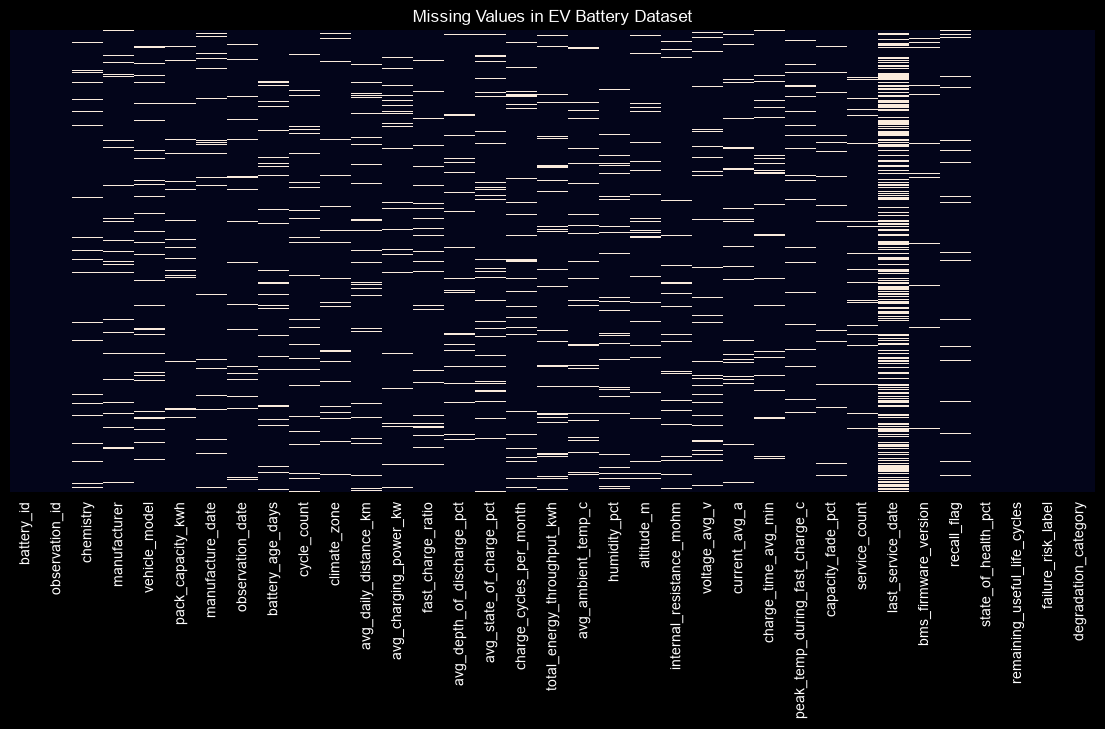

In [60]:
display(df.head())
# dataset dimension
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
# column information
df.info()

# Missing value
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    )
})

display(missing_report)

# duplicate records
print("Duplicate records:", df.duplicated().sum())

# statistical summary
display(df.describe(include="all").T)

# Visualize missing value
plt.figure(figsize=(14, 6))
sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in EV Battery Dataset")
plt.show()

## 5. Data Quality Analysis

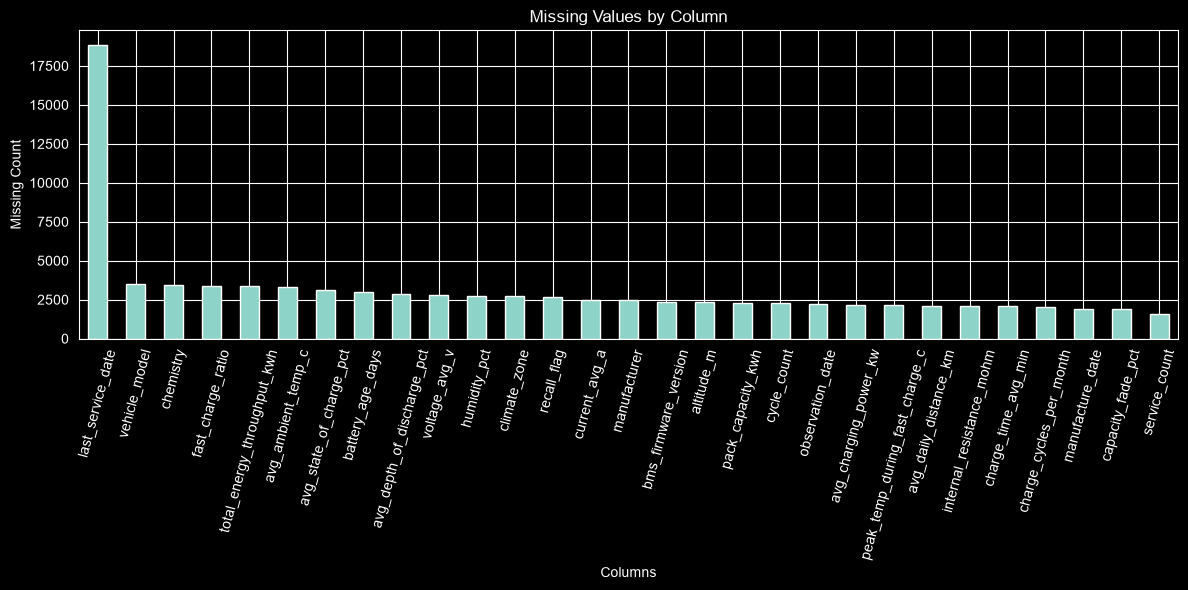

Total duplicate rows: 0
Duplicate observation IDs: 0


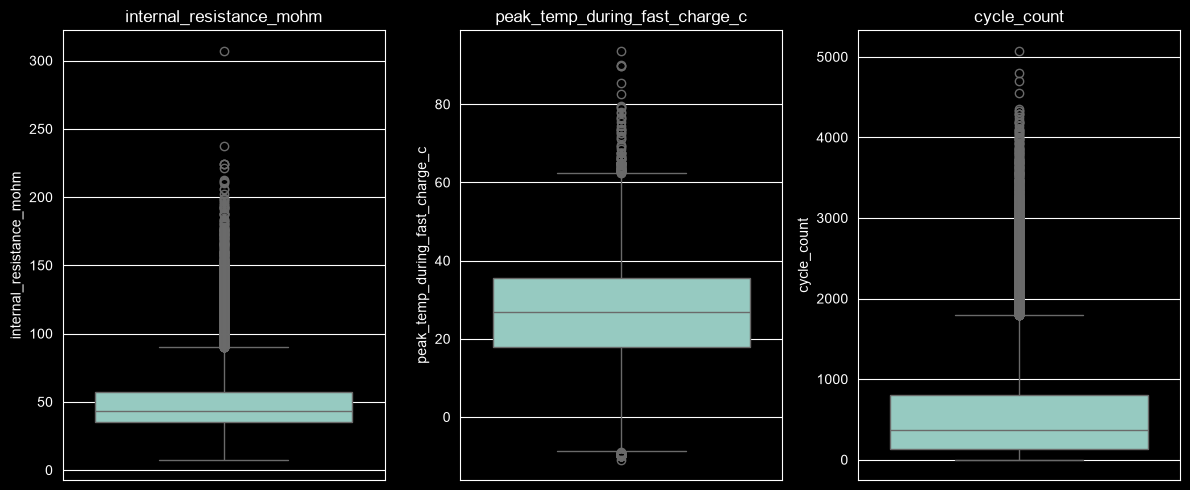

failure_risk_label
Low       42735
Medium     4409
High       2856
Name: count, dtype: int64


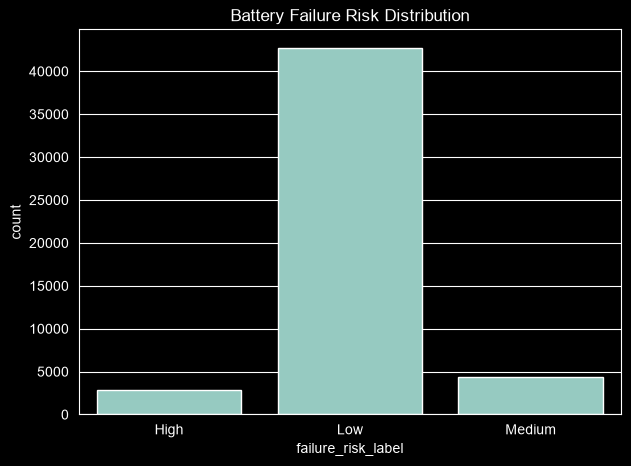

failure_risk_label
Low       85.470
Medium     8.818
High       5.712
Name: proportion, dtype: float64


In [61]:
missing = df.isnull().sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
missing[missing > 0].plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Count")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()
print("Total duplicate rows:", df.duplicated().sum())

print("Duplicate observation IDs:",
      df["observation_id"].duplicated().sum())

columns = [
    "internal_resistance_mohm",
    "peak_temp_during_fast_charge_c",
    "cycle_count"
]

plt.figure(figsize=(12, 5))

for i, col in enumerate(columns):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

print(df["failure_risk_label"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="failure_risk_label"
)

plt.title("Battery Failure Risk Distribution")
plt.show()

print(
    df["failure_risk_label"]
    .value_counts(normalize=True) * 100
)

## 6. Data Cleaning and Pre-processing

In [62]:

df_clean = df_raw.copy()

print("Original shape:", df_raw.shape)
print("Working copy shape:", df_clean.shape)

# Step 1: Identify batteries that have never been serviced
df_clean["never_serviced"] = (
    df_clean["last_service_date"].isnull().astype(int)
)

print("Never serviced distribution:")
print(df_clean["never_serviced"].value_counts())

# Step 2: Handle missing numerical values using median
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical columns:", numeric_cols)

numeric_missing = [
    col for col in numeric_cols
    if df_clean[col].isnull().sum() > 0
]

for col in numeric_missing:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

print("Numerical missing values handled")

# Step 3: Handle missing categorical values using mode
categorical_cols = df_clean.select_dtypes(
    include=["object", "str"]
).columns.tolist()

for col in categorical_cols:
    if col == "last_service_date":
        continue

    if df_clean[col].isnull().sum() > 0:
        mode_value = df_clean[col].mode()[0]
        df_clean[col] = df_clean[col].fillna(mode_value)

print("Categorical missing values handled")

# Step 4: Display missing-value summary
print("Missing values before cleaning:",
      df_raw.isnull().sum().sum())

print("Missing values after cleaning:",
      df_clean.isnull().sum().sum())

display(
    df_clean.isnull().sum()
    .sort_values(ascending=False)
    .head(10)
)


Original shape: (50000, 35)
Working copy shape: (50000, 35)
Never serviced distribution:
never_serviced
0    31169
1    18831
Name: count, dtype: int64
Numerical columns: ['pack_capacity_kwh', 'battery_age_days', 'cycle_count', 'avg_daily_distance_km', 'avg_charging_power_kw', 'fast_charge_ratio', 'avg_depth_of_discharge_pct', 'avg_state_of_charge_pct', 'charge_cycles_per_month', 'total_energy_throughput_kwh', 'avg_ambient_temp_c', 'humidity_pct', 'altitude_m', 'internal_resistance_mohm', 'voltage_avg_v', 'current_avg_a', 'charge_time_avg_min', 'peak_temp_during_fast_charge_c', 'capacity_fade_pct', 'service_count', 'recall_flag', 'state_of_health_pct', 'remaining_useful_life_cycles', 'never_serviced']
Numerical missing values handled
Categorical missing values handled
Missing values before cleaning: 90142
Missing values after cleaning: 18831


last_service_date    18831
battery_id               0
chemistry                0
observation_id           0
manufacturer             0
vehicle_model            0
manufacture_date         0
pack_capacity_kwh        0
battery_age_days         0
cycle_count              0
dtype: int64

In [63]:
# Check duplicate rows
duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

# Remove duplicates
df_clean = df_clean.drop_duplicates()

print("Shape after removing duplicates:", df_clean.shape)

Duplicate rows found: 0
Shape after removing duplicates: (50000, 36)


## 6. Outlier Detection and Handling

Outliers are values that differ significantly from the majority of observations.
They may occur due to unusual battery behaviour, measurement errors, or extreme operating conditions.

In this stage, outliers are detected using the Interquartile Range (IQR) method.

In [64]:
# Select numerical columns, excluding target and binary columns
target_cols = [
    "state_of_health_pct",
    "remaining_useful_life_cycles"
]

outlier_cols = [
    col for col in df_clean.select_dtypes(include=np.number).columns
    if col not in target_cols and col != "recall_flag"
]

# Calculate outliers using IQR
outlier_counts = {}

for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ).sum()

    outlier_counts[col] = count

# Display outlier counts
outlier_summary = pd.Series(outlier_counts).sort_values(
    ascending=False
)

print("Outliers detected in each numerical column:")
display(outlier_summary)

Outliers detected in each numerical column:


charge_time_avg_min               3585
total_energy_throughput_kwh       3107
internal_resistance_mohm          2940
cycle_count                       2757
altitude_m                        2641
capacity_fade_pct                 2593
avg_daily_distance_km             2499
service_count                     1520
avg_charging_power_kw             1436
battery_age_days                  1015
current_avg_a                      894
charge_cycles_per_month            660
fast_charge_ratio                  552
avg_state_of_charge_pct            506
avg_ambient_temp_c                 410
peak_temp_during_fast_charge_c     322
humidity_pct                       283
avg_depth_of_discharge_pct         265
voltage_avg_v                      161
pack_capacity_kwh                    0
never_serviced                       0
dtype: int64

In [65]:
# Handle outliers by capping extreme values
for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Outlier handling completed using IQR capping.")

Outlier handling completed using IQR capping.


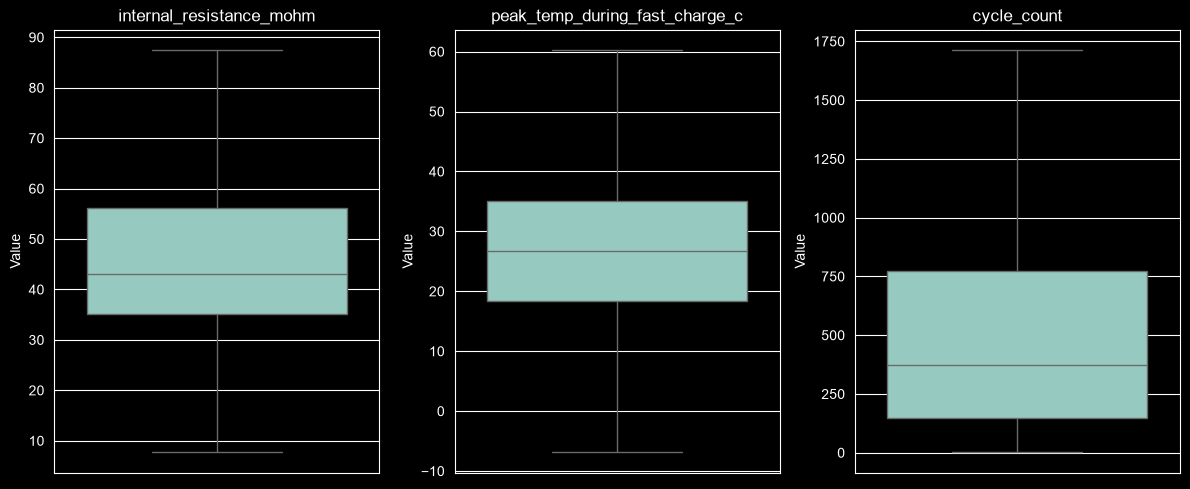

In [66]:
# Compare boxplots after outlier handling
selected_cols = [
    "internal_resistance_mohm",
    "peak_temp_during_fast_charge_c",
    "cycle_count"
]

plt.figure(figsize=(12, 5))

for i, col in enumerate(selected_cols):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df_clean[col])
    plt.title(col)
    plt.ylabel("Value")

plt.tight_layout()
plt.show()

## 7. Data Integration

Data integration is the process of combining data from multiple sources
into a single dataset.

In this project, the main EV battery dataset is integrated with the
data dictionary to understand and document the meaning of each attribute.

In [67]:
# Match main dataset columns with data dictionary
integration_check = pd.DataFrame({
    "column": df_clean.columns
}).merge(
    data_dictionary,
    on="column",
    how="left",
    indicator=True
)

print("Total columns in working dataset:", len(df_clean.columns))
print("Columns matched with dictionary:",
      (integration_check["_merge"] == "both").sum())

print("\nColumns not found in dictionary:")
display(
    integration_check[integration_check["_merge"] == "left_only"][
        ["column"]
    ]
)

print("\nIntegrated metadata preview:")
display(integration_check.head(10))

Total columns in working dataset: 36
Columns matched with dictionary: 35

Columns not found in dictionary:


,column
35,never_serviced



Integrated metadata preview:


,column,dtype,unit,description,example_value,_merge
0,battery_id,string,-,Unique identifier for a physical battery pack ...,BATT_00123,both
1,observation_id,string,-,Unique identifier for a single longitudinal ob...,OBS_004521,both
2,chemistry,categorical,-,"Cell chemistry: LFP, NMC, NCA, or LMO",NMC,both
3,manufacturer,categorical,-,Battery pack manufacturer (synthetic brand names),VoltaCore,both
4,vehicle_model,categorical,-,EV model/platform the pack is installed in,Crossover-X2,both
5,pack_capacity_kwh,float,kWh,Nominal (rated new) pack energy capacity,75.4,both
6,manufacture_date,date,YYYY-MM-DD,Date the battery pack was manufactured,2022-11-23,both
7,observation_date,date,YYYY-MM-DD,Date of this telemetry/health observation,2024-10-16,both
8,battery_age_days,int,days,Days elapsed since manufacture at time of obse...,693,both
9,cycle_count,int,cycles,Cumulative equivalent full charge cycles at ti...,991,both


In [68]:
# Check duplicate entries in data dictionary
print(
    "Duplicate dictionary entries:",
    data_dictionary["column"].duplicated().sum()
)

Duplicate dictionary entries: 0


## 8. Data Transformation

Data transformation converts data into a suitable format for analysis.

In this stage, numerical features are normalized using Min-Max Scaling.
This transforms numerical values into a common range between 0 and 1.

In [69]:
# Select numerical columns for normalization
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

numeric_features = [
    col for col in df_clean.select_dtypes(include=np.number).columns
    if col not in [
        "recall_flag",
        "state_of_health_pct",
        "remaining_useful_life_cycles"
    ]
]

# Create a separate transformed dataset
df_transformed = df_clean.copy()

df_transformed[numeric_features] = scaler.fit_transform(
    df_transformed[numeric_features]
)

print("Min-Max normalization completed!")

display(df_transformed[numeric_features].head())

Min-Max normalization completed!


,pack_capacity_kwh,battery_age_days,cycle_count,avg_daily_distance_km,avg_charging_power_kw,fast_charge_ratio,avg_depth_of_discharge_pct,avg_state_of_charge_pct,charge_cycles_per_month,total_energy_throughput_kwh,...,humidity_pct,altitude_m,internal_resistance_mohm,voltage_avg_v,current_avg_a,charge_time_avg_min,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,never_serviced
0,0.141667,0.394639,0.577891,0.950182,0.384274,0.471956,0.545996,0.478516,0.630011,0.377345,...,0.559978,0.447761,1.000000,0.519817,0.593085,0.129175,0.083333,0.910302,0.8,0.0
1,0.358333,0.376960,0.895440,0.732280,1.000000,0.778386,0.658504,0.177734,1.000000,0.780550,...,0.275843,1.000000,0.529454,0.393293,0.907979,0.121341,0.181548,0.389722,0.0,1.0
2,0.551667,0.241232,0.236994,0.340219,1.000000,0.876881,0.620119,0.548828,0.751432,0.259112,...,0.408513,0.285878,0.378534,0.669207,0.703723,0.135143,0.419643,0.119914,0.0,1.0
3,0.593333,0.018249,0.016344,0.319158,1.000000,0.815321,0.114494,0.724609,0.348225,0.216858,...,0.634052,0.003444,0.443411,0.460366,0.634574,0.047482,0.412202,0.039020,0.0,1.0
4,0.878333,0.295979,0.188544,0.165249,0.487584,0.752394,0.434811,0.552734,0.341352,0.241891,...,0.687120,0.236510,0.759780,0.647866,0.732447,0.275027,0.699405,0.387342,0.0,1.0


## 9. Data Discretization

Data discretization is the process of converting continuous numerical
values into a limited number of categories.

In this project, battery State of Health (SOH) is divided into
three categories: Healthy, Moderate, and Poor.

SOH categories created:
soh_category
Healthy     43739
Moderate     5541
Poor          720
Name: count, dtype: int64


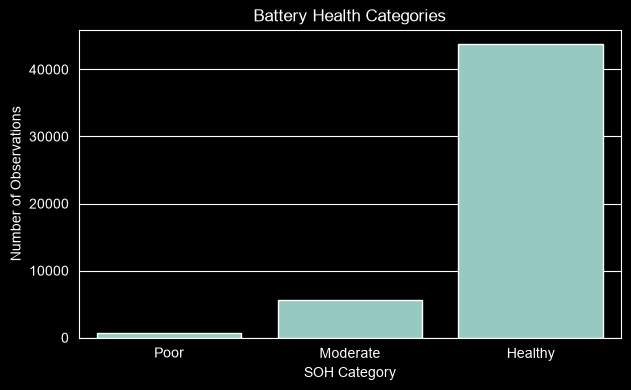

In [70]:
# Discretize battery State of Health
df_transformed["soh_category"] = pd.cut(
    df_transformed["state_of_health_pct"],
    bins=[-float("inf"), 70, 85, float("inf")],
    labels=["Poor", "Moderate", "Healthy"]
)

print("SOH categories created:")
print(df_transformed["soh_category"].value_counts())

# Visualize categories
plt.figure(figsize=(7, 4))
sns.countplot(
    data=df_transformed,
    x="soh_category",
    order=["Poor", "Moderate", "Healthy"]
)
plt.title("Battery Health Categories")
plt.xlabel("SOH Category")
plt.ylabel("Number of Observations")
plt.show()

## 10. Data Reduction

Data reduction decreases the volume or complexity of data while
preserving important information.

In this project, identifier columns that do not provide numerical
analytical value are removed from a separate analysis dataset.

In [71]:
# Create a reduced dataset
columns_to_remove = ["battery_id", "observation_id"]

df_reduced = df_transformed.drop(
    columns=columns_to_remove,
    errors="ignore"
)

print("Original shape:", df_transformed.shape)
print("Reduced dataset shape:", df_reduced.shape)

display(df_reduced.head())

Original shape: (50000, 37)
Reduced dataset shape: (50000, 35)


,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,climate_zone,avg_daily_distance_km,...,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category,never_serviced,soh_category
0,LMO,StormCell,Crossover-X2,0.141667,2022-11-23,2024-10-16,0.394639,0.577891,cold,0.950182,...,0.8,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal,0.0,Moderate
1,LFP,VoltaCore,Sedan-E1,0.358333,2023-03-06,2024-12-27,0.376960,0.895440,cold,0.732280,...,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal,1.0,Healthy
2,LFP,IonFlux,Van-E4,0.551667,2025-06-24,2026-02-10,0.241232,0.236994,cold,0.340219,...,0.0,NaN,BMS_v3.0,0.0,97.48,3248,Low,Normal,1.0,Healthy
3,NMC,Amperion,Van-E4,0.593333,2022-08-13,2022-09-15,0.018249,0.016344,cold,0.319158,...,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal,1.0,Healthy
4,NCA,VoltaCore,Hatch-E3,0.878333,2024-09-27,2026-03-01,0.295979,0.188544,hot_arid,0.165249,...,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal,1.0,Healthy


## 11. Statistical Summary

Statistical analysis helps understand the distribution and characteristics
of battery data.

Descriptive statistics such as mean, median, standard deviation,
minimum, and maximum are calculated for numerical attributes.

In [72]:
# Generate statistical summary using cleaned data
numeric_summary = df_clean.describe().T

display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
pack_capacity_kwh,50000.0,72.648198,14.150466,40.000000,63.000,72.600,82.100,100.000
battery_age_days,50000.0,550.049090,457.888052,1.000000,182.000,424.000,811.000,1754.500
cycle_count,50000.0,529.793532,487.565556,1.000000,146.000,371.000,773.250,1714.125
avg_daily_distance_km,50000.0,47.784387,32.409839,3.000000,23.200,39.300,64.500,126.450
avg_charging_power_kw,50000.0,31.650934,16.520463,0.902804,19.500,28.800,41.100,73.500
fast_charge_ratio,50000.0,0.292267,0.164806,0.000000,0.171,0.272,0.395,0.731
avg_depth_of_discharge_pct,50000.0,64.933289,15.128882,24.450000,54.900,65.100,75.200,100.000
avg_state_of_charge_pct,50000.0,67.588562,9.687858,42.100000,61.300,67.800,74.100,93.300
charge_cycles_per_month,50000.0,20.025676,9.853112,2.000000,12.900,18.900,26.000,45.650
total_energy_throughput_kwh,50000.0,34810.229935,32185.161807,36.400000,9690.575,24134.400,50278.175,111159.575


## 12. Class Comparison

Class comparison is used to understand differences between groups
in a dataset.

In this project, battery State of Health (SOH) is compared across
different battery chemistries.

,mean,median,min,max,count
chemistry,,,,,
LFP,96.085338,97.01,74.7,100.0,13945
LMO,89.286930,91.98,55.0,100.0,6885
NCA,91.487163,93.74,55.0,100.0,9727
NMC,92.692091,94.69,55.0,100.0,19443


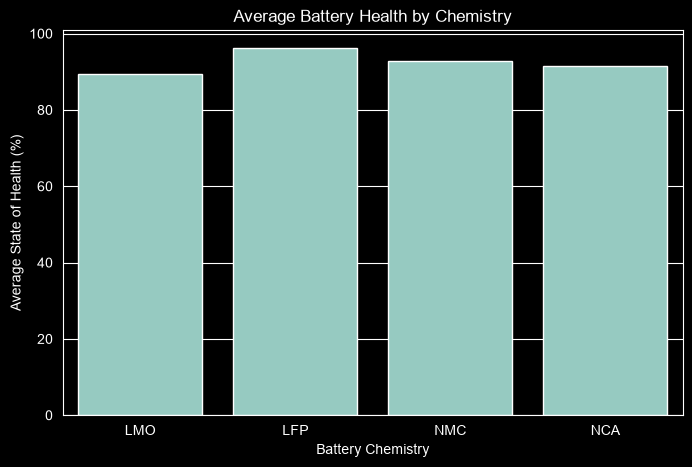

In [73]:
# Compare average battery health by chemistry
chemistry_comparison = df_clean.groupby(
    "chemistry",
    observed=True
)["state_of_health_pct"].agg(
    ["mean", "median", "min", "max", "count"]
)

display(chemistry_comparison)

# Visualize comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="chemistry",
    y="state_of_health_pct",
    estimator="mean",
    errorbar=None
)

plt.title("Average Battery Health by Chemistry")
plt.xlabel("Battery Chemistry")
plt.ylabel("Average State of Health (%)")
plt.show()

## 13. Data Loading

In the loading stage, the processed dataset is exported into a CSV file.
This file can be used for further analysis, visualization, and data mining.

In [74]:
# Export processed dataset
df_reduced.to_csv(
    "ev_battery_cleaned.csv",
    index=False
)

print("Processed dataset exported successfully!")
print("File: ev_battery_cleaned.csv")
print("Final dataset shape:", df_reduced.shape)

Processed dataset exported successfully!
File: ev_battery_cleaned.csv
Final dataset shape: (50000, 35)


## 14. Conclusion

The ETL and data preprocessing pipeline was implemented on the
EV Battery Health and Degradation dataset.

The process included data extraction, profiling, missing-value
handling, duplicate checking, outlier handling, data integration,
normalization, discretization, data reduction, and statistical analysis.

The processed dataset was exported into CSV format and is ready
for further data mining and analysis.

## 15. Final Pipeline Validation

In [75]:
# Final validation
print("========== FINAL PIPELINE VALIDATION ==========")

print("Original dataset shape:", df_raw.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Transformed dataset shape:", df_transformed.shape)
print("Reduced dataset shape:", df_reduced.shape)

print("\nMissing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nProcessed file exists and can be read:")
final_data = pd.read_csv("ev_battery_cleaned.csv")
print(final_data.shape)

print("\nPipeline validation completed.")

========== FINAL PIPELINE VALIDATION ==========
Original dataset shape: (50000, 35)
Cleaned dataset shape: (50000, 36)
Transformed dataset shape: (50000, 37)
Reduced dataset shape: (50000, 35)

Missing values: 18831
Duplicate rows: 0

Processed file exists and can be read:
(50000, 35)

Pipeline validation completed.
